In [1]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy 

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator, GPLightcurveGenerator
from src.selflensing.models import SelfLensingSystem

from src.selflensing.gp import TESSGP

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x11ad5ecf0>

In [3]:
LENSING_METHOD = 'IntegratedWittMao'

In [4]:
sls = SelfLensingSystem(
    a=5 * units.AU,
    i=0.5*numpy.pi * units.rad,
    Macc=10*units.M_sun,
    Mcomp=1 * units.M_sun,
    e=0 * units.dimensionless_unscaled,
    d=1*units.kpc,
)
sls.Rcomp, sls.Tmag, sls.Teff, sls.porb, sls.tau_eff, sls.b, sls.b_max, sls.rE(), sls.i

(Quantity(Array(1., dtype=float64), unit='solRad'),
 Array(14.54931266, dtype=float64),
 Quantity(Array(5772.0034291, dtype=float64), unit='K'),
 Quantity(Array(1231.28075327, dtype=float64), unit='d'),
 Quantity(Array(0.47466526, dtype=float64), unit='d'),
 Quantity(Array(2.17903123e-13, dtype=float64), unit=''),
 Quantity(Array(4.30985665, dtype=float64), unit=''),
 Quantity(Array(2.10190372e+08, dtype=float64), unit='m'),
 Quantity(Array(1.57079633, dtype=float64), unit='rad'))

In [5]:
peak_time = Time("2025-01-03")
start_time = peak_time - sls.tau_eff / 2
end_time = peak_time + sls.tau_eff / 2
# start_time = Time("2025-01-01")
# end_time = Time("2025-01-05")

start_time, peak_time, end_time

(<Time object: scale='utc' format='iso' value=2025-01-02 18:18:14.461>,
 <Time object: scale='utc' format='iso' value=2025-01-03 00:00:00.000>,
 <Time object: scale='utc' format='iso' value=2025-01-03 05:41:45.539>)

In [ ]:
lcg = GPLightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP)
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>


In [7]:
# pyplot.scatter(lcg.times.jd, lcg.flux_array, s=2, alpha=0.5, c='blue')
# pyplot.plot(lcg.times.jd, lcg.flux_array - lcg.gp.generate(), c='red')

In [8]:
# model_sls = SelfLensingSystem(
#     a=5 * units.AU,
#     i=0.45*numpy.pi * units.rad,
#     Macc=10*units.M_sun,
#     Mcomp=5 * units.M_sun,
#     e=0 * units.dimensionless_unscaled,
#     d=10*units.kpc,
# )
# plain_lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6)
# model_plain_lcg = LightcurveGenerator(model_sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6)

In [9]:
# model_lcg = GPLightcurveGenerator(model_sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP)
# model_lcg.gp.condition(lcg.flux_array)

In [10]:
# model_lcg = GPLightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP)
# model_lcg.gp.condition(lcg.flux_array)

(Array([136285.21933305, 136285.23486319, 136285.25043533, ...,
        136285.46234515, 136285.44688215, 136285.43146112], dtype=float64),
 array([723.06032139, 723.06032139, 723.06032139, ..., 723.06032139,
        723.06032139, 723.06032139], shape=(3888,)))

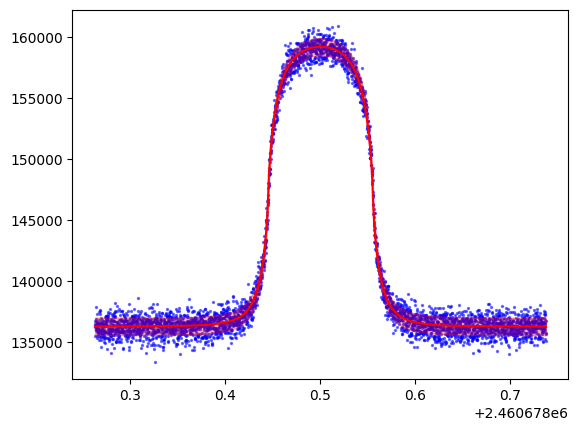

In [11]:
# scale_factor = numpy.mean(lcg.gp.generate())
pyplot.scatter(lcg.times.jd, lcg.flux_array  , s=2, alpha=0.5, c='blue')
# pyplot.plot(plain_lcg.times.jd, plain_lcg.flux_array, c='green')
# model_gp_f = model_lcg.gp.generate()
# pyplot.scatter(model_lcg.times.jd,( 1+(lcg.flux_array - model_gp_f)/numpy.mean(model_gp_f)), c='red', s=2, alpha=0.5,)
mu = lcg.gp.model.loc
std = numpy.sqrt(lcg.gp.model.variance)
pyplot.plot(lcg.times.jd, mu , c='red')
pyplot.fill_between(lcg.times.jd, mu + std, mu - std, color="red", alpha=0.3)
# pyplot.plot(model_plain_lcg.times.jd, model_plain_lcg.flux_array, c='orange')
# pyplot.xlim((peak_time.jd - sls.tau_eff.value/2, peak_time.jd + sls.tau_eff.value/2))
mu, std

In [12]:
# gp_theta, sampler = tgp.fit()
# gp_theta

In [13]:
# max(sampler.get_log_prob(flat=True))

In [14]:
# import jax

# from src.selflensing.gp import LensingGP as lgp
# mag_lc = lgp.build_model_additive(
#     gp_theta, 
#     5, 
#     lgp.make_kernel_fn('GS'), 
#     lcg.time_offsets, 
#     include_lens_mean=0, 
#     noise_measure=tgp.noise_measure,
# )
# mag_samp = mag_lc.sample(jax.random.PRNGKey(tgp.seed))

# plt=pyplot
# # Plot the noise-only model
# plt.figure()
# # plt.errorbar(TESS_times_27/(24 * 60 * 60), noise_samp, yerr=noise_measure, ls = 'none', color = 'grey')
# plt.plot(lcg.times.jd, mag_samp, label='Noise-only model', marker ='o', markersize=2, linestyle = 'None', color='black', alpha=0.5)
# plt.xlabel('Time [days]')
# plt.ylabel('Flux')
# plt.show()

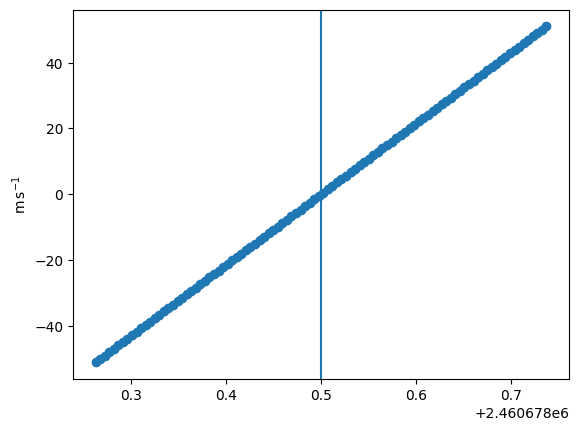

In [15]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.axvline(peak_time.jd)

## Orbital period detection

In [16]:
# import numpy
# peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
# min_mag = peak_mag * 0.999
# max_mag = peak_mag * 1.001
# min_mag, peak_mag, max_mag

In [17]:
# non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [18]:
# from src.selflensing.porb import estimate_porb

# p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
# p

In [19]:
# from astropy import units
# bin_starts = units.Quantity(p[0])
# bin_ends = units.Quantity(p[1])
# bin_counts = numpy.array(p[2])
# total_count = sum(bin_counts)

# bin_widths = bin_ends - bin_starts
# bin_centres = (bin_starts + bin_ends) / 2
# n_density = (bin_counts/total_count) / bin_widths.to(units.year).value

# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [20]:
# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.yscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [21]:
# from src.selflensing.porb import LENS_MASS_DIST
# mass_bin_width = LENS_MASS_DIST[0, 1] - LENS_MASS_DIST[0, 0]
# pyplot.plot(LENS_MASS_DIST[0,:], LENS_MASS_DIST[1,:] / mass_bin_width)
# pyplot.axvline(sls.Macc.to(units.M_sun).value)

## Fitting

In [22]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=rvg.rv/10,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    gp_model=TESSGP,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    tau_eff=sls.tau_eff,
    d=sls.d,
    # period_min=350 * units.day,
    # detect_periods=True,
    nsteps=5000,
    # nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)


detected periods: []
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>


  0%|          | 0/5000 [00:00<?, ?it/s]

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>


/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [1:09:02<00:00,  1.21it/s]


In [23]:
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD, bins=27*24*6)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

In [24]:
lp = sampler.get_log_prob(flat=True)
min(lp), max(lp), lp

(np.float64(-inf),
 np.float64(-20116480303.485447),
 array([-9.06446717e+12, -8.68787831e+12, -8.05917446e+11, ...,
                   -inf,            -inf,            -inf], shape=(500000,)))

In [25]:
sls_fit.a.value, sls_fit.i.value, sls_fit.Macc.value, sls_fit.e.value, sls_fit.periapsis_phase.value

(Array(168.75346297, dtype=float64),
 Array(1.57079628, dtype=float64),
 Array(49.9999995, dtype=float64),
 Array(0.99999897, dtype=float64),
 Array(3.141593, dtype=float64))

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>


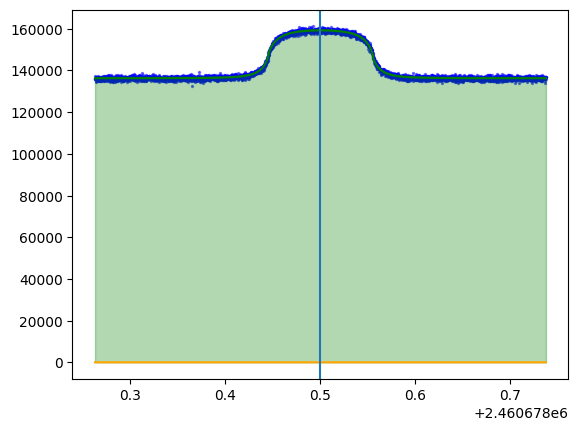

In [26]:
scale = numpy.mean(lcg.gp.generate())
pyplot.scatter(lcg.times.jd, lcg.flux_array , s=2, alpha=0.5, c='blue') # Normalised observed light curve
# pyplot.plot(plain_lcg.times.jd, plain_lcg.flux_array, c='green') # Observed Lensing
pyplot.plot(lcg.times.jd, mu , c='green')
pyplot.fill_between(lcg.times.jd, (mu + std), (mu - std)/scale, color="green", alpha=0.3)
# pyplot.plot(model_lcg.times.jd, 1+(lcg.flux_array - model_lcg.gp.generate())/numpy.mean(model_lcg.gp.generate()), c='red')
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='orange') # Fitted lensing
pyplot.axvline(peak_time.jd)

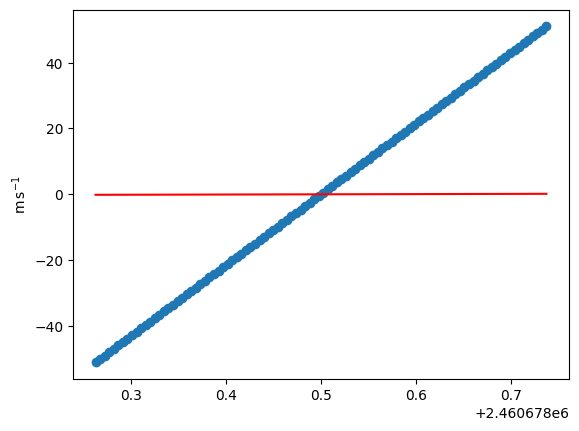

In [27]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

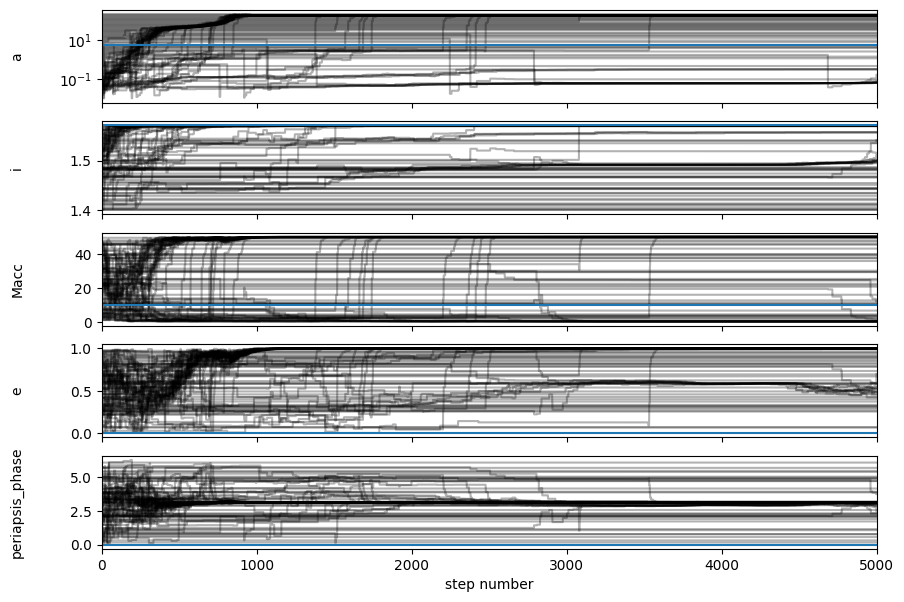

In [28]:
truths=[sls.a.value, sls.i.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]

from matplotlib import pyplot as plt
labels = ["a", "i", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.axhline(truths[i])
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)
axes[0].set_yscale('log')

axes[-1].set_xlabel("step number")

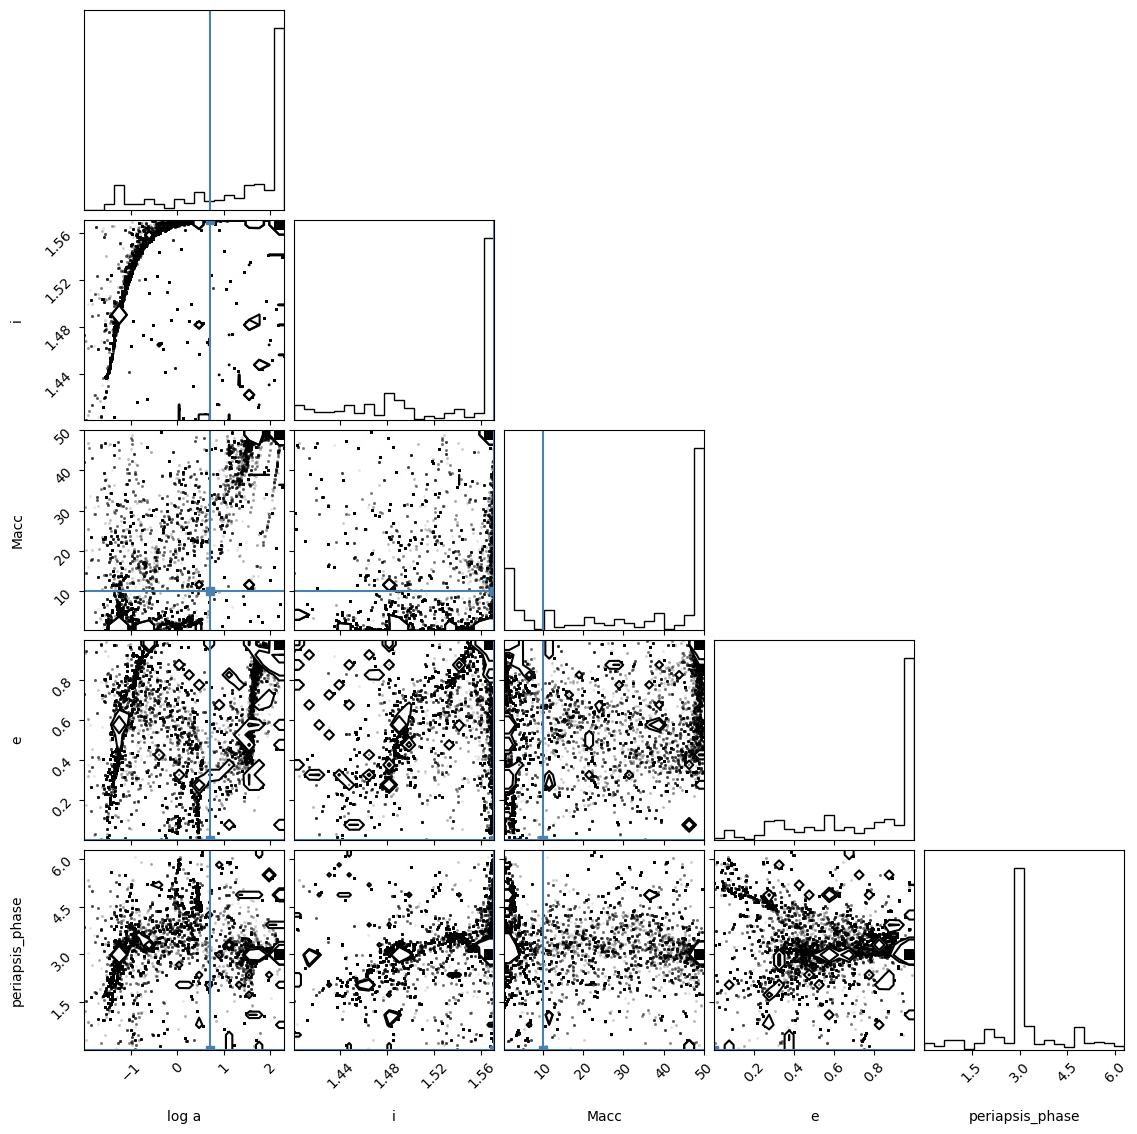

In [29]:
import corner

flat_samples_log = flat_samples.copy()
flat_samples_log[:, 0] = numpy.log10(flat_samples[:, 0])
truths_log = truths.copy()
truths_log[0] = numpy.log10(truths[0])
labels_log = labels.copy()
labels_log[0] = 'log ' + labels[0]
fig = corner.corner(
    flat_samples_log, labels=labels_log, truths=truths_log
)